# Lesson 4.7: Plotly Visualization

**Analyst:** Meron Welderufael
**Date:** 11/17/2026
**Client:** FinFlow (Product Analytics engagement led by Hannah Whitford)
**Notebook purpose:** Produce the visualization deck for Friday's product
leadership review. Single HTML file output with monthly signup trend,
cohort churn pattern, tier comparison, and one supporting chart.

In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)

df = pd.read_csv(
    'finflow-enriched-200k.csv',
    parse_dates=['signup_date', 'last_login_date', 'churn_date']
)

cohort_churn = pd.read_csv(
    'cohort-churn-by-signup-month.csv'
)
print(f"Customer Data: {df.shape}")
print(f"Cohort churn data: {cohort_churn.shape}")

Customer Data: (200000, 22)
Cohort churn data: (25, 4)


## Panel 1: Cohort churn trend.
A line chart of churn_rate_pct by signup_cohort, using the cohort_churn data from Lesson 4.6. Markers on, line color firebrick (a dark red), with a callout annotation on the most recent three cohorts explaining the "less time-at-risk" effect. Title: "Churn rate by signup cohort."

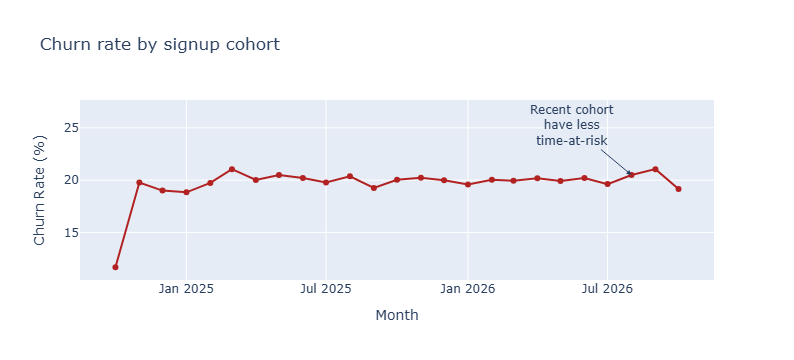

In [2]:
# Make sure signup_cohort is treated as a string for plotting
cohort_churn['signup_cohort_str'] = cohort_churn['signup_cohort'].astype(str)

fig_cohort_churn = px.line(
    cohort_churn,
    x='signup_cohort_str',
    y='churn_rate_pct',
    title='Churn rate by signup cohort',
    labels= {
        'signup_cohort_str': 'Month',
        'churn_rate_pct': 'Churn Rate (%)'
    },
    color_discrete_sequence=['firebrick'],
    markers=True
)
fig_cohort_churn.update_layout(showlegend=False)

fig_cohort_churn.add_annotation(
    x=cohort_churn['signup_cohort_str'].iloc[-3],
    y=cohort_churn['churn_rate_pct'].iloc[-3],
    text='Recent cohort<br> have less <br>time-at-risk',
    showarrow=True,
    arrowhead=2,
    ax=-60,
    ay=-50
)
fig_cohort_churn.show()


## Panel 2: Cohort-by-tier breakdown.
A multi-line chart showing churn_rate_pct by signup_cohort, one line per marketing_name. Use the cohort-by-tier-breakdown.csv you produced in Lesson 4.6's Practice Exercise (load it explicitly). If the loaded file is in wide format from unstack, melt it back to long format with melt (the technique from Lesson 4.5) before passing to Plotly. Title: "Churn rate by signup cohort and tier."

Cohort by tier data: (27, 7)
  signup_cohort   marketing_name churn_rate_pct
0       2024-10  Enterprise Plus            0.0
1       2024-11  Enterprise Plus           4.65
2       2024-12  Enterprise Plus           3.59
3       2025-01  Enterprise Plus           3.33
4       2025-02  Enterprise Plus            4.9
5       2025-03  Enterprise Plus           5.52
6       2025-04  Enterprise Plus           4.66
7       2025-05  Enterprise Plus           4.03
8       2025-06  Enterprise Plus           6.03
9       2025-07  Enterprise Plus           4.69


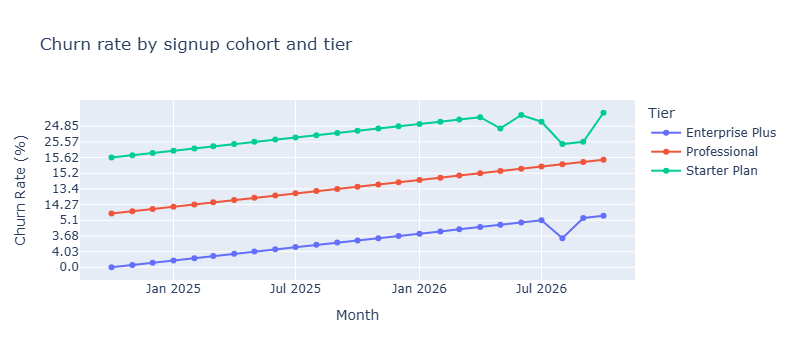

In [3]:
# Load the file cohort-by-tier
cohort_by_tier = pd.read_csv(
    'cohort-by-tier-breakdown.csv'
)
print(f"Cohort by tier data: {cohort_by_tier.shape}")
cohort_by_tier

# Remove the two header rows
cohort = cohort_by_tier.iloc[2:].copy()

# Select churn percentage columns
churn_cols = cohort.columns[4:7]

# Melt wide format into long format
cohort_long = cohort.melt(
    id_vars='Unnamed: 0',
    value_vars=churn_cols,
    var_name='tier_column',
    value_name='churn_value'
)

# Rename columns
cohort_long = cohort_long.rename(columns={
    'Unnamed: 0': 'signup_cohort',
    'churn_value': 'churn_rate_pct'
})

# Map original column names to marketing names
cohort_long['marketing_name'] = cohort_long['tier_column'].map({
    'churn_rate_pct': 'Enterprise Plus',
    'churn_rate_pct.1': 'Professional',
    'churn_rate_pct.2': 'Starter Plan'
})

# Keep only the four relevant columns
cohort_long = cohort_long[
    ['signup_cohort', 'marketing_name', 'churn_rate_pct']
]

print(cohort_long.head(10))

fig = px.line(
    cohort_long,
    x='signup_cohort',
    y='churn_rate_pct',
    color='marketing_name',
    markers=True,
    title='Churn rate by signup cohort and tier',
    labels= {
        'signup_cohort': 'Month',
        'churn_rate_pct': 'Churn Rate (%)',
        'marketing_name': 'Tier'
    },
)

fig.show()

## Panel 3: Monthly signup trend with smoothing.
The layered Graph Objects chart from Step 8 of the Guided Example, reproduced. Gray monthly line, steelblue rolling-3-month average overlay. Title: "Monthly signups with smoothed trend."

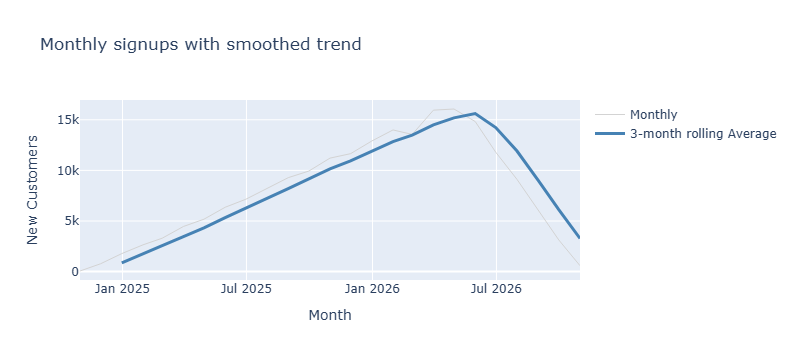

In [4]:
monthly_signups =(
    df.set_index('signup_date')
    .resample('ME')
    .size()
    .reset_index(name='signups')
)

monthly_signups['signups_smoothed']=monthly_signups['signups'].rolling(window=3).mean()

fig_signup_layered = go.Figure()

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups'],
    mode='lines',
    name='Monthly',
    line=dict(color = 'lightgray', width=1)
))

fig_signup_layered.add_trace(go.Scatter(
    x=monthly_signups['signup_date'],
    y=monthly_signups['signups_smoothed'],
    mode = 'lines',
    name='3-month rolling Average',
    line=dict(color = 'steelblue', width=3)
))

fig_signup_layered.update_layout(
    title = 'Monthly signups with smoothed trend',
    xaxis_title = 'Month',
    yaxis_title = 'New Customers'
)
fig_signup_layered.show()

## Panel 4: A chart of your choice that supports the story.
Pick one chart from the lesson (bar, histogram, box plot, faceted line, or scatter) that adds something the other three panels don't. Justify the choice in one sentence in a markdown cell.

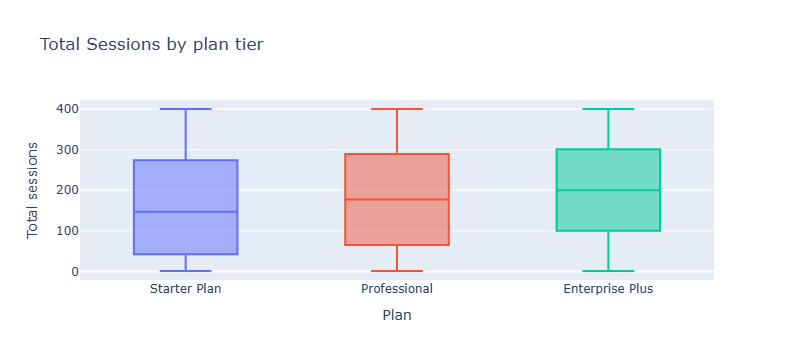

In [5]:
fig_session_box = px.box(
    df,
    x='marketing_name',
    y='total_sessions',
    color='marketing_name',
    title='Total Sessions by plan tier',
    labels={
        'marketing_name': 'Plan',
        'total_sessions': 'Total sessions'
    }
)
fig_session_box.update_layout(showlegend=False)
fig_session_box.show()

I would choose the box plot because it shows the distribution of total sessions across plan tiers, including the median, spread, and potential outliers, which the other charts don't clearly reveal.

saved file


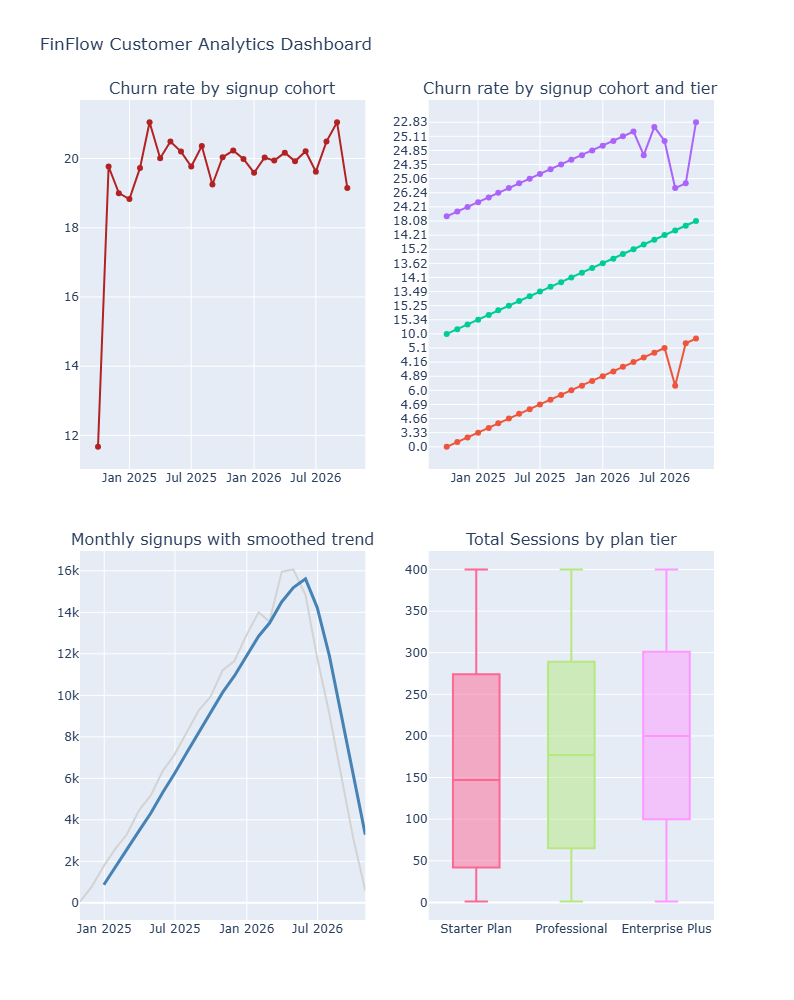

In [6]:
#Combine into a single HTML
deck = make_subplots(
    rows=2, cols=2,
    subplot_titles= [
        'Churn rate by signup cohort',
        'Churn rate by signup cohort and tier',
        'Monthly signups with smoothed trend',
        'Total Sessions by plan tier'
    ],
     vertical_spacing=0.10
)
# Chart 1: Overall cohort churn
deck.add_trace(
    go.Scatter(
        x=cohort_churn['signup_cohort'].astype(str),
        y=cohort_churn['churn_rate_pct'],
        mode='lines+markers',
        name='Overall churn',
        line=dict(color='firebrick')
    ),
    row=1, col=1
)

# Chart 2: Cohort churn by tier

for tier in cohort_long['marketing_name'].unique():
    tier_data = cohort_long[
        cohort_long['marketing_name'] == tier
    ]

    deck.add_trace(
        go.Scatter(
            x=tier_data['signup_cohort'].astype(str),
            y=tier_data['churn_rate_pct'],
            mode='lines+markers',
            name=tier
        ),
        row=1, col=2
    )

# Chart 3: Monthly signups
deck.add_trace(
    go.Scatter(
        x=monthly_signups['signup_date'],
        y=monthly_signups['signups'],
        mode='lines',
        name='Monthly signups',
        line=dict(color='lightgray')
    ),
    row=2, col=1
)

deck.add_trace(
    go.Scatter(
        x=monthly_signups['signup_date'],
        y=monthly_signups['signups_smoothed'],
        mode='lines',
        name='3-month average',
        line=dict(color='steelblue', width=3)
    ),
    row=2, col=1
)

# Chart 4: Total sessions by plan tier
for tier in df['marketing_name'].unique():
    deck.add_trace(
        go.Box(
            y=df.loc[
                df['marketing_name'] == tier,
                'total_sessions'
            ],
            name=tier
        ),
        row=2, col=2
    )

# Dashboard layout
deck.update_layout(
    title='FinFlow Customer Analytics Dashboard',
    height=1000,
    showlegend=False
)

deck.write_html("finflow-friday-deck-final.html")
print('saved file')
deck.show()

**What's the headline insight from the four panels combined?**

The four panels bring the key churn patterns together in one view, allowing product leadership to understand the overall situation within a few minutes. They show how churn changes across signup cohorts and plan tiers, making it easier to identify patterns and areas that may need attention.

**single question would you want product leadership to answer after they look at this?**

The main question I would want product leadership to answer is: What actions should we prioritize to reduce churn, particularly among the plan tiers or customer cohorts showing higher churn?